# Kesit İstatistik — Ağaçlar, topluluklar ve derin öğrenme

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Karar ağaçları ve safsızlık

Daha derin ağaç neden daha iyi test sonucu vermeyebilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Derinliğe göre eğitim/test kaybını karşılaştır.

**Yorum sınırı:** Ağaç parametreleri testten seçilmez; tek bölme genelleme belirsizliğini özetlemez.

**Alıştırma:** min_samples_leaf değerini 1’den 10’a çıkar; aşırı uyumu incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


  derinlik  egitim_hata  test_hata
0        1     0.120513   0.161905
1        2     0.076923   0.142857
2        3     0.061538   0.138095
3        5     0.030769   0.133333
4        9     0.000000   0.157143
5     None     0.000000   0.157143


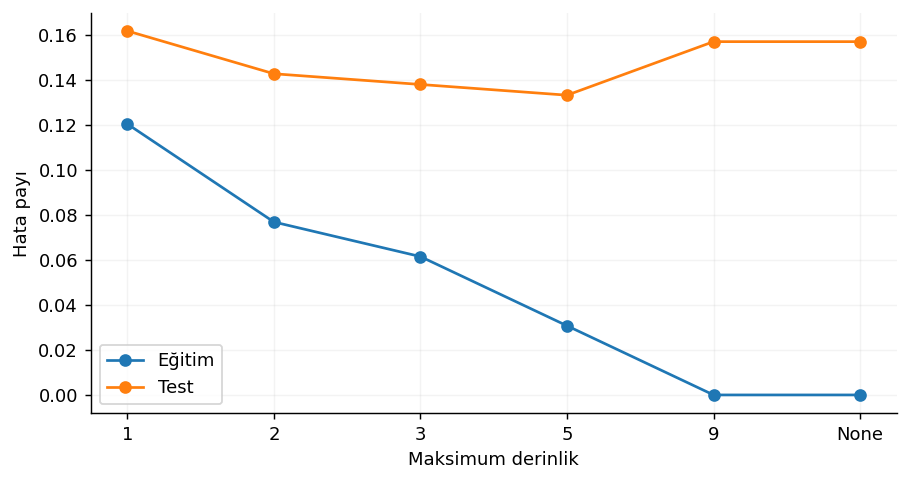

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.tree import DecisionTreeClassifier
X,y=make_classification(n_samples=600,n_features=6,n_informative=3,flip_y=.1,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);rows=[]
for depth in [1,2,3,5,9,None]:
 m=DecisionTreeClassifier(max_depth=depth,random_state=7);m.fit(a,c);rows.append([str(depth),1-m.score(a,c),1-m.score(b,d)])
t=pd.DataFrame(rows,columns=['derinlik','egitim_hata','test_hata']);print(t);plt.plot(t.derinlik,t.egitim_hata,'o-',label='Eğitim');plt.plot(t.derinlik,t.test_hata,'o-',label='Test');plt.xlabel('Maksimum derinlik');plt.ylabel('Hata payı');plt.legend()

## Bagging, rastgele orman ve korelasyon

Toplulukta ağaç sayısı kadar korelasyon neden önemli?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** max_features değişince tek ağaç tahminlerinin korelasyonunu ve orman başarısını birlikte oku.

**Yorum sınırı:** Korelasyon aynı test noktalarında tanımlıdır; hata korelasyonu ve tahmin korelasyonu farklıdır.

**Alıştırma:** Ağaç sayısını 80’den 10’a indir; korelasyonun tek açıklayıcı olmadığını göster.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


  max_features  tahmin_korelasyonu  test_dogruluk
0         sqrt            0.622355       0.910204
1          1.0            0.706773       0.902041


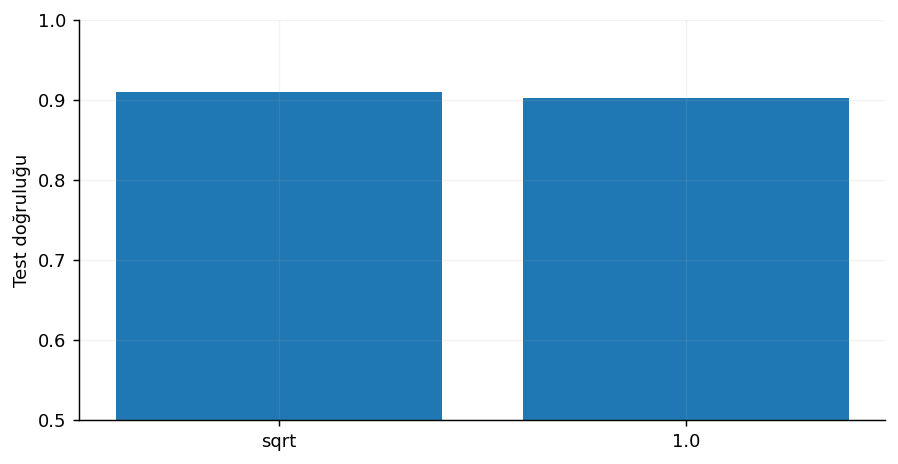

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.ensemble import RandomForestClassifier
X,y=make_classification(n_samples=700,n_features=12,n_informative=4,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);rows=[]
for features in ['sqrt',1.0]:
 m=RandomForestClassifier(n_estimators=80,max_features=features,min_samples_leaf=3,random_state=7,n_jobs=1);m.fit(a,c);p=np.array([tree.predict_proba(b)[:,1] for tree in m.estimators_]);corr=np.corrcoef(p);off=corr[np.triu_indices_from(corr,1)];rows.append([str(features),np.nanmean(off),m.score(b,d)])
print(pd.DataFrame(rows,columns=['max_features','tahmin_korelasyonu','test_dogruluk']));plt.bar([r[0] for r in rows],[r[2] for r in rows]);plt.ylim(.5,1);plt.ylabel('Test doğruluğu')

## Boosting ve eklemeli öğrenme

Boosting adımları ne zaman aşırı uyuma döner?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Sabit ayarda adım sayısı boyunca eğitim ve test log kaybını izle.

**Yorum sınırı:** Test eğrisi öğretim gözlemidir; üretimde erken durdurma ayrı doğrulama verisinden seçilir.

**Alıştırma:** Öğrenme hızını .1’den .03’e düşür; aynı adım sayısının anlamını tartış.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'son_egitim': 0.12188235705062388, 'son_test': 0.4224757007496858}


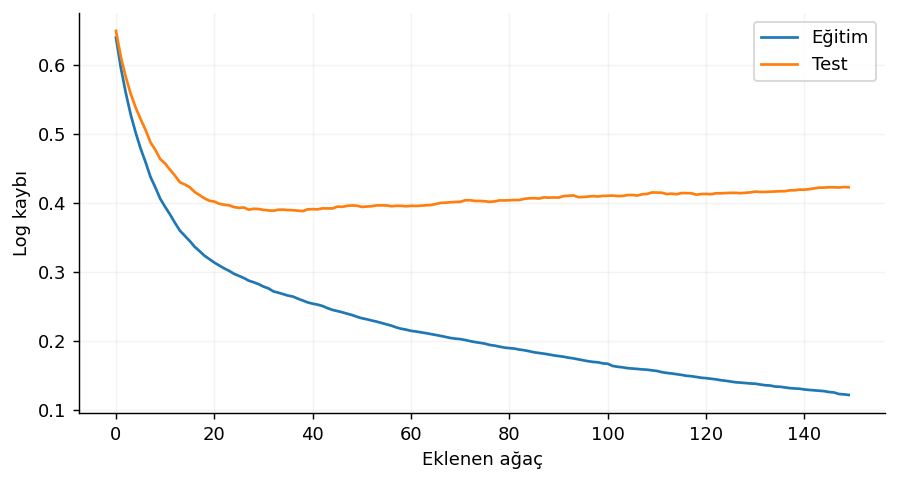

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.ensemble import GradientBoostingClassifier
X,y=make_classification(n_samples=600,n_features=8,n_informative=4,flip_y=.1,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);m=GradientBoostingClassifier(n_estimators=150,learning_rate=.1,max_depth=2,random_state=7);m.fit(a,c);train=[log_loss(c,p) for p in m.staged_predict_proba(a)];test=[log_loss(d,p) for p in m.staged_predict_proba(b)];print({'son_egitim':train[-1],'son_test':test[-1]});plt.plot(train,label='Eğitim');plt.plot(test,label='Test');plt.xlabel('Eklenen ağaç');plt.ylabel('Log kaybı');plt.legend()

## Sinir ağlarının istatistiksel temeli

Ağ kapasitesi ve ceza birlikte nasıl değerlendirilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı testte farklı ağların kaybını eğitim kaybıyla karşılaştır.

**Yorum sınırı:** Küçük MLP öğretim modelidir; derin öğrenmenin bütün mimarilerini temsil etmez. Yakınsama uyarısı model tanısıdır.

**Alıştırma:** alpha=.01 yerine 1 kullan; model karmaşıklığı ve kaybı karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   gizli_birim  egitim_logloss  test_logloss
0            4        0.493039      0.461874
1           16        0.536314      0.517628
2           48        0.531449      0.499694


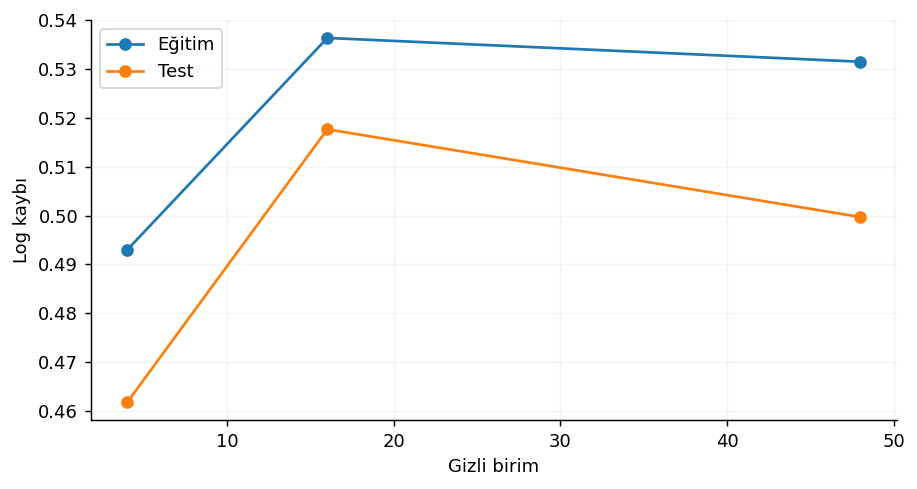

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.neural_network import MLPClassifier
X,y=make_moons(n_samples=500,noise=.25,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);rows=[]
for width in [4,16,48]:
 m=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(width,),alpha=.01,max_iter=1200,early_stopping=True,n_iter_no_change=30,random_state=7));m.fit(a,c);rows.append([width,log_loss(c,m.predict_proba(a)),log_loss(d,m.predict_proba(b))])
t=pd.DataFrame(rows,columns=['gizli_birim','egitim_logloss','test_logloss']);print(t);plt.plot(t.gizli_birim,t.egitim_logloss,'o-',label='Eğitim');plt.plot(t.gizli_birim,t.test_logloss,'o-',label='Test');plt.xlabel('Gizli birim');plt.ylabel('Log kaybı');plt.legend()